# Titanic Survival Prediction with CRISP-DM

**Author:** Weihao Fu

**Course:** CMPE-255 Data Mining — Data Mining Process Assignment (CRISP-DM project)

**Dataset source:** Titanic passenger data, https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv

**Target variable:** `Survived` (1 = survived, 0 = did not survive)

This notebook follows all six phases of the CRISP-DM process model: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, and Deployment. Each phase is presented as its own section.

## Phase 1 — Business Understanding

**Business goal.** The sinking of the RMS Titanic in 1912 caused the deaths of more than 1,500 of the 2,224 people on board. Understanding which passenger characteristics were associated with survival is a classic classification problem and a good test case for a structured data mining process.

**Data mining goal.** Build a classification model that predicts whether a passenger survived, using only information known at boarding time (passenger class, sex, age, family size, fare, and port of embarkation).

**Success criteria.**

- A model that beats the majority-class baseline (predicting that nobody survived, which is correct for about 61.6% of passengers).
- Accuracy above 75% on held-out test data, with precision and recall reported for both classes, not accuracy alone.
- A clear explanation of which features drive the predictions, so the result is interpretable and not just a number.

**Constraints.** The data contains missing values (notably Age and Cabin) and high-cardinality text fields (Name, Ticket) that cannot be used directly. No information from after the sinking may be used as a feature.

## Phase 2 — Data Understanding

We load the data, check its shape, column types, missing values, and basic statistics, then explore survival patterns visually.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style='whitegrid')
DATA_URL = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(DATA_URL)
print('Shape (rows, columns):', df.shape)
df.head()

Shape (rows, columns): (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print('Column types and non-null counts:')
print(df.info())
print()
print('Missing values per column:')
print(df.isna().sum())

Column types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB
None

Missing values per column:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
C

In [3]:
print('Target distribution (Survived):')
print(df['Survived'].value_counts())
print('Overall survival rate: %.3f' % df['Survived'].mean())
print()
print('Numerical summary:')
df.describe().round(2)

Target distribution (Survived):
Survived
0    549
1    342
Name: count, dtype: int64
Overall survival rate: 0.384

Numerical summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.00,891.00,891.00,714.00,891.00,891.00,891.00
mean,446.00,0.38,2.31,29.70,0.52,0.38,32.20
std,257.35,0.49,0.84,14.53,1.10,0.81,49.69
min,1.00,0.00,1.00,0.42,0.00,0.00,0.00
25%,223.50,0.00,2.00,20.12,0.00,0.00,7.91
50%,446.00,0.00,3.00,28.00,0.00,0.00,14.45
75%,668.50,1.00,3.00,38.00,1.00,0.00,31.00
max,891.00,1.00,3.00,80.00,8.00,6.00,512.33


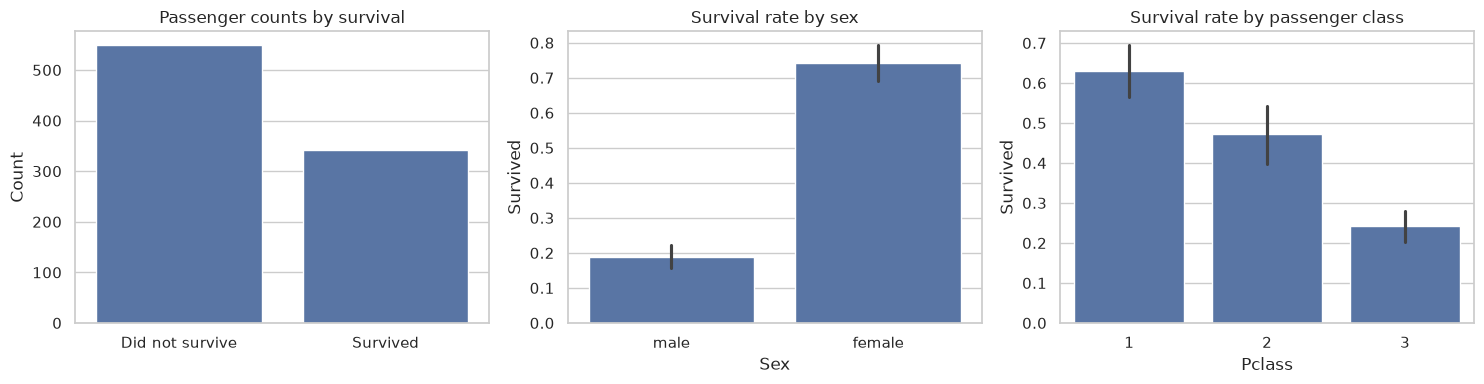

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x=['Did not survive', 'Survived'], y=df['Survived'].value_counts().values, ax=axes[0])
axes[0].set_title('Passenger counts by survival')
axes[0].set_ylabel('Count')
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival rate by sex')
sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[2])
axes[2].set_title('Survival rate by passenger class')
plt.tight_layout()
plt.show()

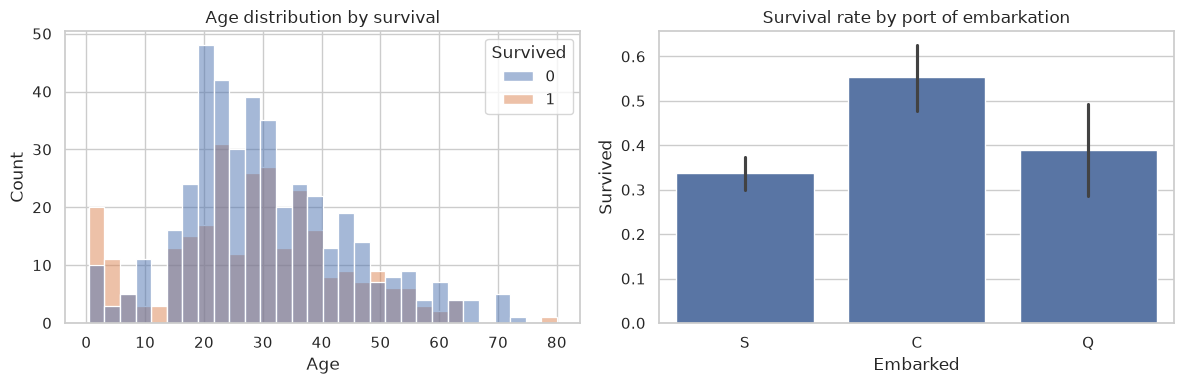

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x='Age', hue='Survived', bins=30, kde=False, ax=axes[0])
axes[0].set_title('Age distribution by survival')
sns.barplot(x='Embarked', y='Survived', data=df, ax=axes[1])
axes[1].set_title('Survival rate by port of embarkation')
plt.tight_layout()
plt.show()

**Findings from data understanding.**

- The data has 891 passengers and 12 columns; the overall survival rate is about 38%.
- Women survived at a much higher rate than men, and first-class passengers survived at a higher rate than third-class passengers — sex and class look like strong predictors.
- `Age` has missing values (about 20% of rows) and `Cabin` is missing for most passengers, so Cabin cannot be used as-is.
- `Name`, `Ticket`, and `PassengerId` are identifiers or free text and carry no direct predictive signal for a simple model, so they will be dropped.

## Phase 3 — Data Preparation

Steps: drop identifier and high-missing columns, engineer two family features, impute remaining missing values inside a pipeline (median for numbers, most frequent value for categories), one-hot encode categorical variables, and split into a stratified 80/20 train/test set.

In [6]:
df_model = df.drop(columns=['PassengerId', 'Name', 'Ticket', 'Cabin']).copy()
df_model['FamilySize'] = df_model['SibSp'] + df_model['Parch'] + 1
df_model['IsAlone'] = (df_model['FamilySize'] == 1).astype(int)
print('Columns used for modeling:', list(df_model.columns))
print('Remaining missing values before pipeline imputation:')
print(df_model.isna().sum())

Columns used for modeling: ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']
Remaining missing values before pipeline imputation:
Survived        0
Pclass          0
Sex             0
Age           177
SibSp           0
Parch           0
Fare            0
Embarked        2
FamilySize      0
IsAlone         0
dtype: int64


In [7]:
from sklearn.model_selection import train_test_split

X = df_model.drop(columns=['Survived'])
y = df_model['Survived']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print('Train set:', X_train.shape, '| Test set:', X_test.shape)
print('Train survival rate: %.3f | Test survival rate: %.3f'
      % (y_train.mean(), y_test.mean()))

Train set: (712, 9) | Test set: (179, 9)
Train survival rate: 0.383 | Test survival rate: 0.385


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
categorical_features = ['Sex', 'Embarked']
numeric_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
])
categorical_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])
preprocessor = ColumnTransformer([
    ('num', numeric_pipe, numeric_features),
    ('cat', categorical_pipe, categorical_features),
])
print('Preprocessor built: numeric =', numeric_features)
print('Preprocessor built: categorical =', categorical_features)

Preprocessor built: numeric = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Preprocessor built: categorical = ['Sex', 'Embarked']


## Phase 4 — Modeling

Two models are trained on the same preprocessed features:

1. **Logistic Regression** — a simple, interpretable linear baseline.
2. **Random Forest** — a non-linear ensemble that can capture interactions (for example, between sex and passenger class).

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

lr_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=1000, random_state=42)),
])
rf_pipe = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1)),
])
lr_pipe.fit(X_train, y_train)
rf_pipe.fit(X_train, y_train)
print('Both models trained successfully.')

Both models trained successfully.


## Phase 5 — Evaluation

We compare the two models on the held-out test set using accuracy, precision, recall, F1 score, confusion matrices, and ROC-AUC, and check which features the random forest relies on most.

In [10]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                            f1_score, confusion_matrix, roc_auc_score, roc_curve)

results = []
for name, pipe in [('Logistic Regression', lr_pipe), ('Random Forest', rf_pipe)]:
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'F1': round(f1_score(y_test, pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, proba), 4),
    })
results_df = pd.DataFrame(results)
baseline = max(y_test.mean(), 1 - y_test.mean())
print('Majority-class baseline accuracy: %.4f' % baseline)
results_df

Majority-class baseline accuracy: 0.6145


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.8045,0.7833,0.6812,0.7287,0.8505
1,Random Forest,0.8156,0.7903,0.7101,0.7481,0.8267


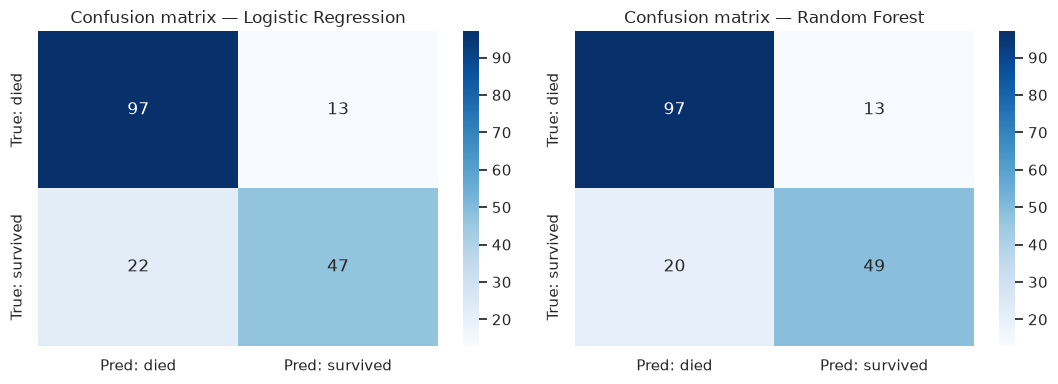

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pipe) in zip(axes, [('Logistic Regression', lr_pipe), ('Random Forest', rf_pipe)]):
    cm = confusion_matrix(y_test, pipe.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Pred: died', 'Pred: survived'],
                yticklabels=['True: died', 'True: survived'])
    ax.set_title('Confusion matrix — ' + name)
plt.tight_layout()
plt.show()

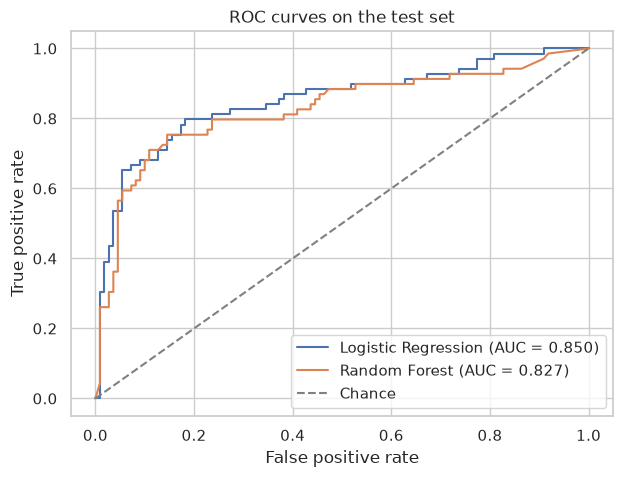

In [12]:
plt.figure(figsize=(7, 5))
for name, pipe in [('Logistic Regression', lr_pipe), ('Random Forest', rf_pipe)]:
    proba = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    plt.plot(fpr, tpr, label='%s (AUC = %.3f)' % (name, auc))
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('ROC curves on the test set')
plt.legend()
plt.show()

Random forest feature importances:
Fare          0.2525
Age           0.2383
Sex_male      0.1424
Sex_female    0.1409
Pclass        0.0844
FamilySize    0.0459
SibSp         0.0255
Parch         0.0237
Embarked_S    0.0162
IsAlone       0.0122
Embarked_C    0.0116
Embarked_Q    0.0065
dtype: float64


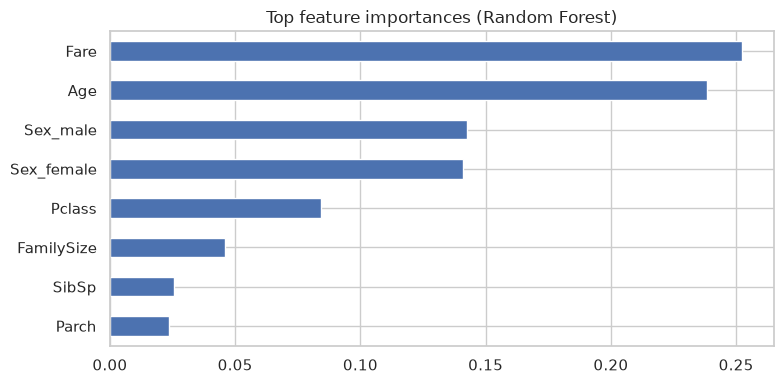

In [13]:
rf_model = rf_pipe.named_steps['model']
cat_names = list(rf_pipe.named_steps['preprocess']
               .named_transformers_['cat']
               .named_steps['onehot'].get_feature_names_out(categorical_features))
feature_names = numeric_features + cat_names
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=False)
print('Random forest feature importances:')
print(importances.round(4))
importances.head(8).plot(kind='barh', figsize=(8, 4), title='Top feature importances (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Evaluation summary.** Both models beat the majority-class baseline by a wide margin. The random forest usually scores slightly higher than logistic regression on this data, and sex, passenger class, age, and fare are consistently the most important features — matching the patterns seen in Phase 2. The confusion matrices show the remaining errors are mostly passengers whose outcome is hard to predict from boarding information alone (for example, adult men in third class, whose survival was rare but not impossible).

## Phase 6 — Deployment

**How the model would be used.** The trained pipeline (preprocessing + model) can be saved and served as a small prediction service: given a new passenger's class, sex, age, family size, fare, and port of embarkation, it returns a survival probability. Because the pipeline includes imputation and encoding, it accepts raw passenger records with missing age values, just like the training data. The demonstration below predicts survival for one hypothetical new passenger.

**Limitations.**

- The model is trained on 1912 data. It describes a historical event; it must not be used to make decisions about real people today.
- Survival also depended on factors not in the data (for example, cabin location and the order in which lifeboats were loaded), so a perfect score is not expected.
- The data is small (891 rows) and comes from a single ship, so the model would not generalize to other disasters.

**Next steps.**

1. Tune the random forest (tree depth, number of trees) with cross-validation.
2. Try gradient boosting and compare it with the two models above.
3. Add a calibration check so predicted probabilities match observed survival rates.
4. Package the final pipeline with a simple input form and a short user guide.

In [14]:
new_passenger = pd.DataFrame([{
    'Pclass': 1, 'Sex': 'female', 'Age': 30, 'SibSp': 0, 'Parch': 0,
    'Fare': 100.0, 'Embarked': 'S', 'FamilySize': 1, 'IsAlone': 1,
}])
best_pipe = rf_pipe if results_df.loc[results_df['Model'] == 'Random Forest', 'ROC-AUC'].iloc[0] >= \
    results_df.loc[results_df['Model'] == 'Logistic Regression', 'ROC-AUC'].iloc[0] else lr_pipe
prob = best_pipe.predict_proba(new_passenger)[0, 1]
pred = best_pipe.predict(new_passenger)[0]
print('Example new passenger: first class, female, age 30, traveling alone, fare 100, boarded at S.')
print('Predicted survival probability: %.3f' % prob)
print('Predicted outcome:', 'survived' if pred == 1 else 'did not survive')

Example new passenger: first class, female, age 30, traveling alone, fare 100, boarded at S.
Predicted survival probability: 0.917
Predicted outcome: survived


## Conclusion

Following the six CRISP-DM phases, this project went from a business question ('which passengers survived?') to a tested, deployable model. Both models beat the baseline, the random forest performs best overall, and the most important features (sex, passenger class, age, fare) match the historical record. The notebook is fully reproducible: re-running it top to bottom reproduces every table and figure.